# CA1 - Image Processing Notebook - Section 1
1) بارگذاری و مشخصات تصویر
2) تبدیل به RGB، Grayscale، Binary
3) تبدیل به HSV
4) تفکیک کانال‌های RGB و HSV
5) تعریف و محاسبه کنتراست + افزایش/کاهش کنتراست
6) تعریف و رسم هیستوگرام
7) Histogram Equalization و Histogram Stretching

In [ ]:
# !pip install opencv-python matplotlib numpy

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.grid'] = False

Image path: Pic.jpg
Format (extension): .jpg
Shape (H, W, C): (633, 800, 3)
Data type: uint8
Number of channels: 3


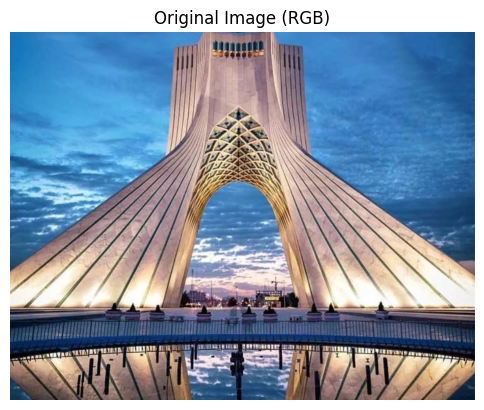

In [ ]:
# 1) Load image and report format/type/channels
img_path = 'Pic.jpg'

if not os.path.exists(img_path):
    raise FileNotFoundError(
        "not found"
    )

img_bgr = cv2.imread(img_path, cv2.IMREAD_COLOR)
if img_bgr is None:
    raise ValueError("not found")

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

h, w, c = img_rgb.shape
dtype = img_rgb.dtype
file_ext = os.path.splitext(img_path)[1].lower()

print('Image path:', img_path)
print('Format (extension):', file_ext)
print('Shape (H, W, C):', img_rgb.shape)
print('Data type:', dtype)
print('Number of channels:', c)

plt.figure(figsize=(6, 5))
plt.imshow(img_rgb)
plt.title('Original Image (RGB)')
plt.axis('off')
plt.show()

### توضیح کوتاه
- **RGB**: هر پیکسل با سه کانال Red, Green, Blue نمایش داده می‌شود.
- **Grayscale**: شدت روشنایی هر پیکسل در یک کانال ذخیره می‌شود.
- **Binary**: تصویر دودویی فقط دو مقدار دارد (مثلاً 0 و 255) که معمولاً با آستانه‌گذاری از grayscale تولید می‌شود.

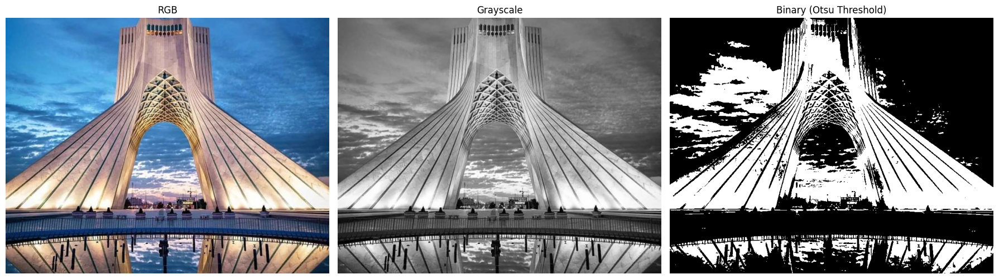

In [ ]:
# 2) RGB -> Grayscale -> Binary
gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

# Otsu ه‌گذاری اتوماتیک با 
_, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].imshow(img_rgb)
axs[0].set_title('RGB')
axs[0].axis('off')

axs[1].imshow(gray, cmap='gray')
axs[1].set_title('Grayscale')
axs[1].axis('off')

axs[2].imshow(binary, cmap='gray')
axs[2].set_title('Binary (Otsu Threshold)')
axs[2].axis('off')

plt.tight_layout()
plt.show()

###  چیست؟ HSV
مدل **HSV** تصویر را با سه مولفه نمایش می‌دهد:
- **H (Hue)**: نوع رنگ (زاویه رنگ)
- **S (Saturation)**: میزان خلوص رنگ
- **V (Value)**: روشنایی

این مدل برای پردازش رنگ (مثل تفکیک رنگ‌ها) معمولاً شهودی‌تر از RGB است.

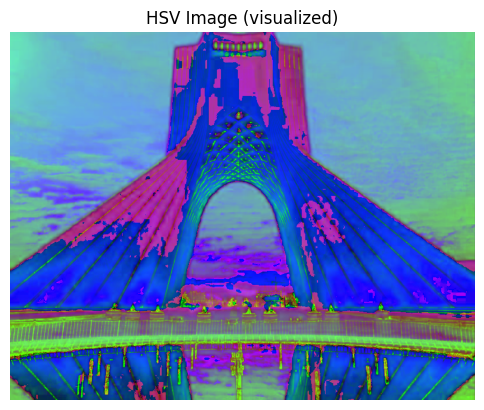

In [ ]:
# 3) Convert RGB to HSV and display
hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)

plt.figure(figsize=(6, 5))
plt.imshow(hsv)
plt.title('HSV Image (visualized)')
plt.axis('off')
plt.show()

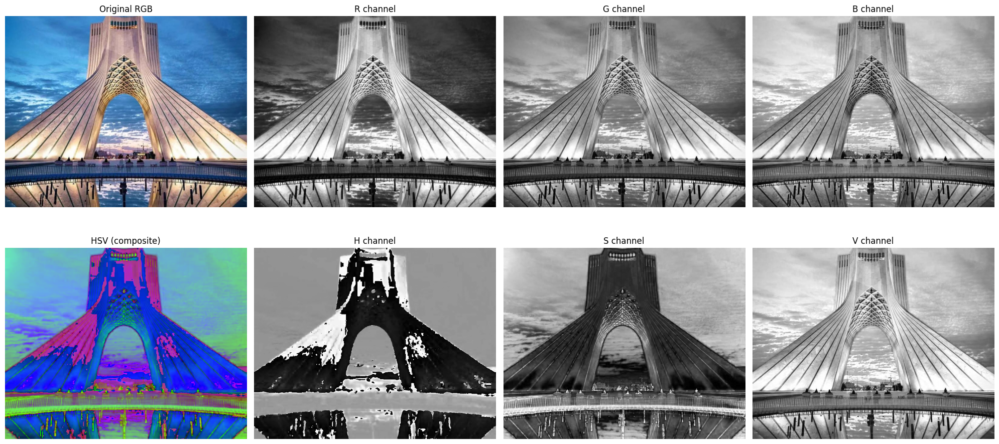

In [ ]:
# 4) Split RGB and HSV channels and show each component
r, g, b = cv2.split(img_rgb)
h_ch, s_ch, v_ch = cv2.split(hsv)

fig, axs = plt.subplots(2, 4, figsize=(20, 10))

axs[0, 0].imshow(img_rgb)
axs[0, 0].set_title('Original RGB')
axs[0, 0].axis('off')

axs[0, 1].imshow(r, cmap='gray')
axs[0, 1].set_title('R channel')
axs[0, 1].axis('off')

axs[0, 2].imshow(g, cmap='gray')
axs[0, 2].set_title('G channel')
axs[0, 2].axis('off')

axs[0, 3].imshow(b, cmap='gray')
axs[0, 3].set_title('B channel')
axs[0, 3].axis('off')

axs[1, 0].imshow(hsv)
axs[1, 0].set_title('HSV (composite)')
axs[1, 0].axis('off')

axs[1, 1].imshow(h_ch, cmap='gray')
axs[1, 1].set_title('H channel')
axs[1, 1].axis('off')

axs[1, 2].imshow(s_ch, cmap='gray')
axs[1, 2].set_title('S channel')
axs[1, 2].axis('off')

axs[1, 3].imshow(v_ch, cmap='gray')
axs[1, 3].set_title('V channel')
axs[1, 3].axis('off')

plt.tight_layout()
plt.show()

### Contrast (کنتراست)
کنتراست نشان می‌دهد شدت روشنایی پیکسل‌ها چقدر از هم فاصله دارند. یک معیار ساده، **انحراف معیار** شدت روشنایی است:

\\[
Contrast = std(I)
\\]

هرچه این مقدار بیشتر باشد، تفاوت روشن و تیره بیشتر است.

Original contrast (std): 54.84
High contrast (std):     63.65
Low contrast (std):      32.91


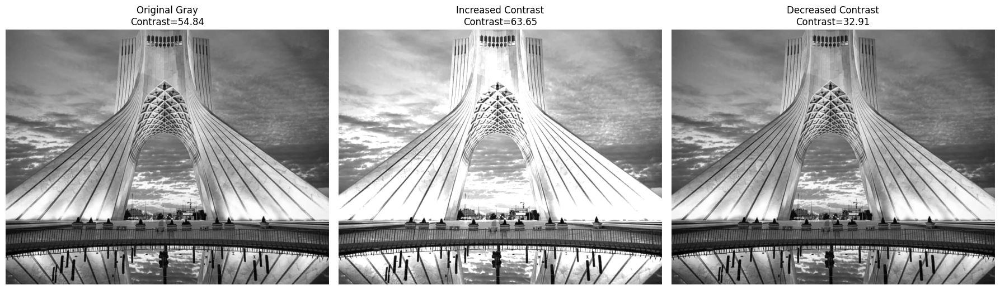

In [ ]:
# 5) Compute contrast and increase/decrease it
contrast_original = float(np.std(gray))

# افزایش کنتراست: alpha > 1
high_contrast = cv2.convertScaleAbs(gray, alpha=1.5, beta=0)

# کاهش کنتراست: 0 < alpha < 1
low_contrast = cv2.convertScaleAbs(gray, alpha=0.6, beta=0)

contrast_high = float(np.std(high_contrast))
contrast_low = float(np.std(low_contrast))

print(f'Original contrast (std): {contrast_original:.2f}')
print(f'High contrast (std):     {contrast_high:.2f}')
print(f'Low contrast (std):      {contrast_low:.2f}')

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].imshow(gray, cmap='gray')
axs[0].set_title(f'Original Gray\nContrast={contrast_original:.2f}')
axs[0].axis('off')

axs[1].imshow(high_contrast, cmap='gray')
axs[1].set_title(f'Increased Contrast\nContrast={contrast_high:.2f}')
axs[1].axis('off')

axs[2].imshow(low_contrast, cmap='gray')
axs[2].set_title(f'Decreased Contrast\nContrast={contrast_low:.2f}')
axs[2].axis('off')

plt.tight_layout()
plt.show()

### Histogram (هیستوگرام تصویر)
هیستوگرام، توزیع فراوانی شدت روشنایی (یا رنگ) را نشان می‌دهد. در تصویر خاکستری، محور افقی شدت (0 تا 255) و محور عمودی تعداد پیکسل‌هاست.

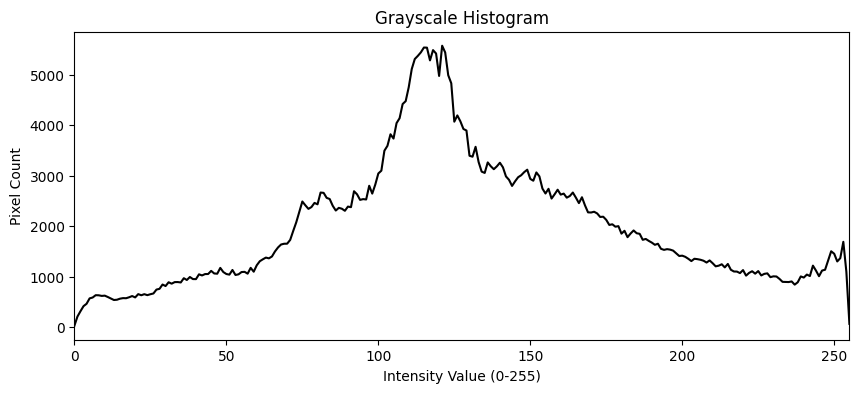

In [ ]:
# 6) Plot image histogram (grayscale)
hist = cv2.calcHist([gray], [0], None, [256], [0, 256])

plt.figure(figsize=(10, 4))
plt.plot(hist, color='black')
plt.title('Grayscale Histogram')
plt.xlabel('Intensity Value (0-255)')
plt.ylabel('Pixel Count')
plt.xlim([0, 255])
plt.show()

### Histogram Equalization و Histogram Stretching
- **Equalization**: توزیع شدت‌ها را بازپخش می‌کند تا کنتراست کلی بهتر شود.
- **Stretching (Normalization)**: بازه شدت تصویر را به بازه کامل `[0,255]` می‌کشد.

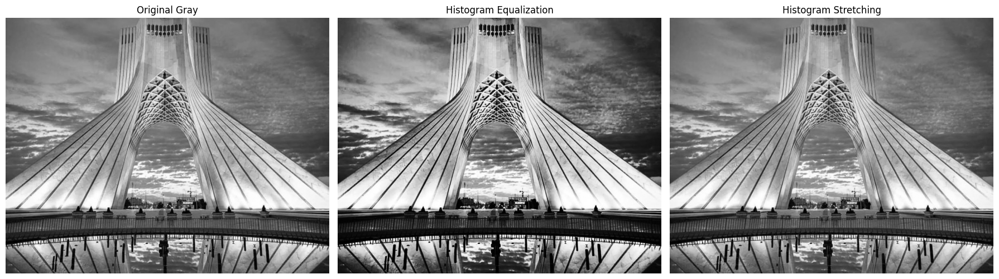

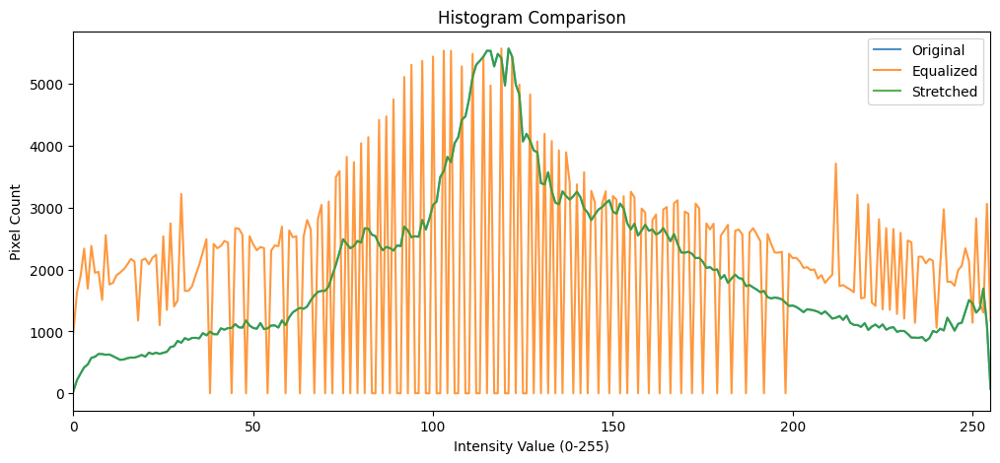

In [ ]:
# 7) Apply Histogram Equalization and Histogram Stretching
equalized = cv2.equalizeHist(gray)
stretched = cv2.normalize(gray, None, 0, 255, cv2.NORM_MINMAX)

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].imshow(gray, cmap='gray')
axs[0].set_title('Original Gray')
axs[0].axis('off')

axs[1].imshow(equalized, cmap='gray')
axs[1].set_title('Histogram Equalization')
axs[1].axis('off')

axs[2].imshow(stretched, cmap='gray')
axs[2].set_title('Histogram Stretching')
axs[2].axis('off')

plt.tight_layout()
plt.show()

# نمایش هیستوگرام هر سه تصویر برای مقایسه
hist_eq = cv2.calcHist([equalized], [0], None, [256], [0, 256])
hist_st = cv2.calcHist([stretched], [0], None, [256], [0, 256])

plt.figure(figsize=(12, 5))
plt.plot(hist, label='Original', alpha=0.8)
plt.plot(hist_eq, label='Equalized', alpha=0.8)
plt.plot(hist_st, label='Stretched', alpha=0.8)
plt.title('Histogram Comparison')
plt.xlabel('Intensity Value (0-255)')
plt.ylabel('Pixel Count')
plt.xlim([0, 255])
plt.legend()
plt.show()

## Section 2

در این بخش نویز، کرنل‌ها، پیاده‌سازی فیلترگذاری دستی و مقایسه با توابع آماده بررسی می‌شود.

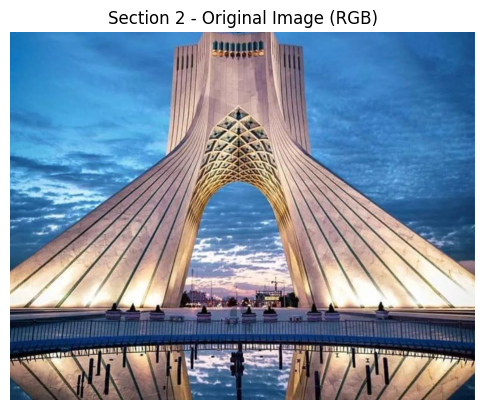

In [ ]:
# 1) بارگذاری مجدد تصویر
img_path = 'Pic.jpg'
img_bgr_2 = cv2.imread(img_path, cv2.IMREAD_COLOR)
if img_bgr_2 is None:
    raise FileNotFoundError('فایل Pic.jpg پیدا نشد. لطفا تصویر را کنار نوت‌بوک قرار دهید.')

img_rgb_2 = cv2.cvtColor(img_bgr_2, cv2.COLOR_BGR2RGB)
gray_2 = cv2.cvtColor(img_rgb_2, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(6, 5))
plt.imshow(img_rgb_2)
plt.title('Section 2 - Original Image (RGB)')
plt.axis('off')
plt.show()

### 2) افزودن نویز
- نویز **Salt and Pepper**: تعدادی پیکسل به طور تصادفی کاملا سفید (salt) یا کاملا سیاه (pepper) می‌شوند.
- نویز رایج دیگر: **Gaussian Noise** که مقدار روشنایی پیکسل‌ها را با نویز نرمال تغییر می‌دهد.

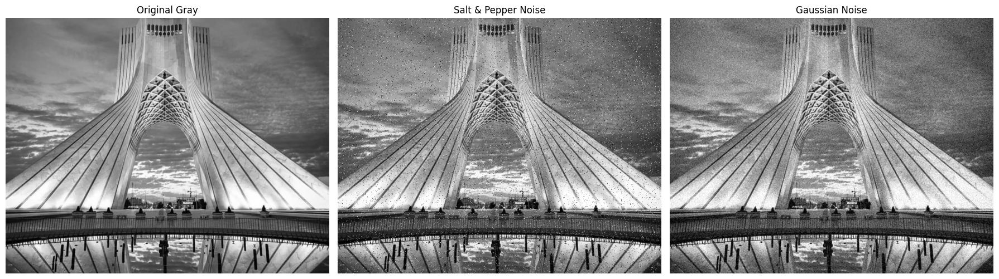

In [ ]:
# 2) Add Salt & Pepper noise + Gaussian noise
rng = np.random.default_rng(42)

# Salt & Pepper روی تصویر خاکستری
sp_noisy = gray_2.copy()
noise_ratio = 0.04  # درصد پیکسل‌های نویزی
num_noise = int(noise_ratio * gray_2.size)

# مختصات pepper
pepper_idx = rng.choice(gray_2.size, size=num_noise // 2, replace=False)
sp_noisy.flat[pepper_idx] = 0

# مختصات salt
salt_idx = rng.choice(gray_2.size, size=num_noise // 2, replace=False)
sp_noisy.flat[salt_idx] = 255

# Gaussian noise
gauss = rng.normal(0, 20, gray_2.shape)
gaussian_noisy = np.clip(gray_2.astype(np.float32) + gauss, 0, 255).astype(np.uint8)

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].imshow(gray_2, cmap='gray')
axs[0].set_title('Original Gray')
axs[0].axis('off')

axs[1].imshow(sp_noisy, cmap='gray')
axs[1].set_title('Salt & Pepper Noise')
axs[1].axis('off')

axs[2].imshow(gaussian_noisy, cmap='gray')
axs[2].set_title('Gaussian Noise')
axs[2].axis('off')

plt.tight_layout()
plt.show()

### 3) مفهوم Kernel
**Kernel** یک ماتریس کوچک (مثلا 3x3 یا 5x5) است که روی تصویر حرکت می‌کند و با همسایه‌های هر پیکسل ترکیب می‌شود تا عملیات‌هایی مثل محوشدگی، شارپ‌سازی و استخراج لبه انجام شود.

### 4) تابع اعمال کرنل (بدون توابع آماده OpenCV)
تابع زیر کانولوشن دوبعدی را برای کرنل‌های با اندازه‌های مختلف انجام می‌دهد.

In [ ]:
# 4) Custom 2D convolution function for any odd kernel size

def apply_kernel_custom(image, kernel):
    if image.ndim != 2:
        raise ValueError('این تابع فقط تصویر تک‌کاناله (grayscale) می‌پذیرد.')

    kh, kw = kernel.shape
    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError('ابعاد کرنل باید فرد باشد (مثل 3x3، 5x5).')

    pad_h, pad_w = kh // 2, kw // 2
    padded = np.pad(image.astype(np.float32), ((pad_h, pad_h), (pad_w, pad_w)), mode='reflect')

    out = np.zeros_like(image, dtype=np.float32)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            region = padded[i:i + kh, j:j + kw]
            out[i, j] = np.sum(region * kernel)

    return np.clip(out, 0, 255).astype(np.uint8)

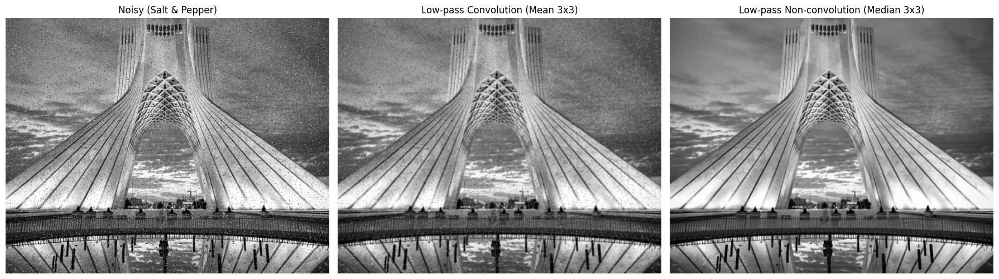

توضیح:
- Mean Filter نویز را کاهش می‌دهد ولی لبه‌ها را کمی محو می‌کند.
- Median Filter برای Salt & Pepper بهتر عمل می‌کند و نقاط پرت را موثرتر حذف می‌کند.


In [ ]:
# 5) Low-pass (smoothing) and non-convolutional low-pass on noisy image

# کرنل پایین‌گذر کانولوشنی (میانگین‌گیر)
kernel_avg_3x3 = np.ones((3, 3), dtype=np.float32) / 9.0
lp_conv = apply_kernel_custom(sp_noisy, kernel_avg_3x3)

# پایین‌گذر غیرکانولوشنی: Median Filter (برای Salt&Pepper بسیار موثر است)
lp_nonconv = cv2.medianBlur(sp_noisy, 3)

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].imshow(sp_noisy, cmap='gray')
axs[0].set_title('Noisy (Salt & Pepper)')
axs[0].axis('off')

axs[1].imshow(lp_conv, cmap='gray')
axs[1].set_title('Low-pass Convolution (Mean 3x3)')
axs[1].axis('off')

axs[2].imshow(lp_nonconv, cmap='gray')
axs[2].set_title('Low-pass Non-convolution (Median 3x3)')
axs[2].axis('off')

plt.tight_layout()
plt.show()

print('توضیح:')
print('- Mean Filter نویز را کاهش می‌دهد ولی لبه‌ها را کمی محو می‌کند.')
print('- Median Filter برای Salt & Pepper بهتر عمل می‌کند و نقاط پرت را موثرتر حذف می‌کند.')

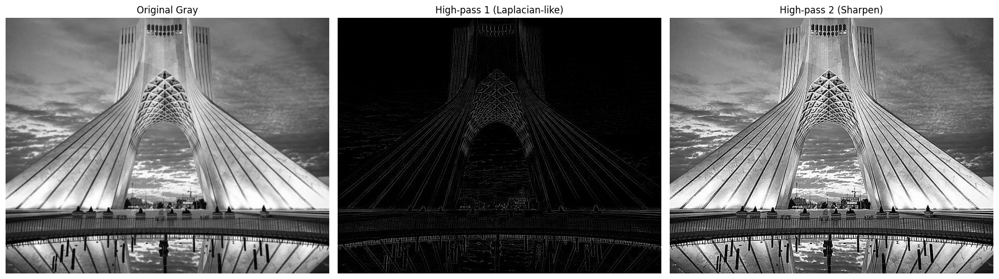

توضیح کوتاه:
- فیلتر اول لبه‌ها را بیشتر برجسته می‌کند.
- فیلتر دوم علاوه بر لبه، حس شارپ‌تر شدن کل تصویر را می‌دهد.


In [ ]:
# 6) Two high-pass filters using custom function

# High-pass 1: Laplacian-like kernel
hp_kernel_1 = np.array([
    [0, -1, 0],
    [-1, 4, -1],
    [0, -1, 0]
], dtype=np.float32)

# High-pass 2: Sharpening kernel
hp_kernel_2 = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

hp1 = apply_kernel_custom(gray_2, hp_kernel_1)
hp2 = apply_kernel_custom(gray_2, hp_kernel_2)

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].imshow(gray_2, cmap='gray')
axs[0].set_title('Original Gray')
axs[0].axis('off')

axs[1].imshow(hp1, cmap='gray')
axs[1].set_title('High-pass 1 (Laplacian-like)')
axs[1].axis('off')

axs[2].imshow(hp2, cmap='gray')
axs[2].set_title('High-pass 2 (Sharpen)')
axs[2].axis('off')

plt.tight_layout()
plt.show()

print('توضیح کوتاه:')
print('- فیلتر اول لبه‌ها را بیشتر برجسته می‌کند.')
print('- فیلتر دوم علاوه بر لبه، حس شارپ‌تر شدن کل تصویر را می‌دهد.')

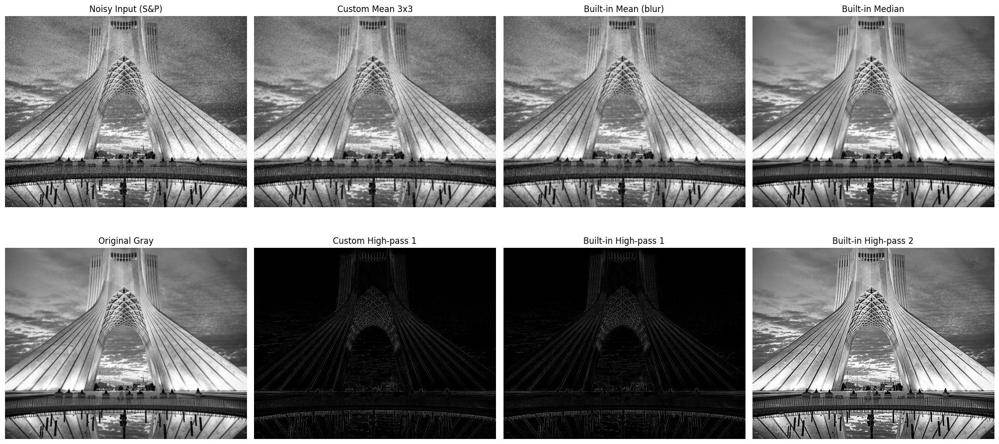

مقایسه نهایی:
- خروجی فیلتر Mean سفارشی با blur آماده بسیار نزدیک است.
- برای Salt & Pepper، Median معمولا بهترین نتیجه را در حذف نویز می‌دهد.
- خروجی فیلترهای High-pass سفارشی و filter2D از نظر رفتاری مشابه‌اند.
- GaussianBlur نسبت به Mean لبه‌ها را کمی طبیعی‌تر نگه می‌دارد.


In [ ]:
# 7) Apply equivalent built-in filters and compare outputs

# Built-in low-pass filters
builtin_mean = cv2.blur(sp_noisy, (3, 3))
builtin_gaussian = cv2.GaussianBlur(sp_noisy, (3, 3), 0)
builtin_median = cv2.medianBlur(sp_noisy, 3)

# Built-in high-pass filters (using filter2D with same kernels)
builtin_hp1 = cv2.filter2D(gray_2, -1, hp_kernel_1)
builtin_hp2 = cv2.filter2D(gray_2, -1, hp_kernel_2)

fig, axs = plt.subplots(2, 4, figsize=(20, 10))

axs[0, 0].imshow(sp_noisy, cmap='gray')
axs[0, 0].set_title('Noisy Input (S&P)')
axs[0, 0].axis('off')

axs[0, 1].imshow(lp_conv, cmap='gray')
axs[0, 1].set_title('Custom Mean 3x3')
axs[0, 1].axis('off')

axs[0, 2].imshow(builtin_mean, cmap='gray')
axs[0, 2].set_title('Built-in Mean (blur)')
axs[0, 2].axis('off')

axs[0, 3].imshow(builtin_median, cmap='gray')
axs[0, 3].set_title('Built-in Median')
axs[0, 3].axis('off')

axs[1, 0].imshow(gray_2, cmap='gray')
axs[1, 0].set_title('Original Gray')
axs[1, 0].axis('off')

axs[1, 1].imshow(hp1, cmap='gray')
axs[1, 1].set_title('Custom High-pass 1')
axs[1, 1].axis('off')

axs[1, 2].imshow(builtin_hp1, cmap='gray')
axs[1, 2].set_title('Built-in High-pass 1')
axs[1, 2].axis('off')

axs[1, 3].imshow(builtin_hp2, cmap='gray')
axs[1, 3].set_title('Built-in High-pass 2')
axs[1, 3].axis('off')

plt.tight_layout()
plt.show()

print('مقایسه نهایی:')
print('- خروجی فیلتر Mean سفارشی با blur آماده بسیار نزدیک است.')
print('- برای Salt & Pepper، Median معمولا بهترین نتیجه را در حذف نویز می‌دهد.')
print('- خروجی فیلترهای High-pass سفارشی و filter2D از نظر رفتاری مشابه‌اند.')
print('- GaussianBlur نسبت به Mean لبه‌ها را کمی طبیعی‌تر نگه می‌دارد.')

## Section 3

در این بخش روی فایل ویدیویی `Original_Vid.mp4` کار می‌کنیم:
1) بارگذاری ویدیو
2) استخراج تعداد فریم‌ها و FPS
3) افزودن نویز Salt & Pepper و ذخیره خروجی
4) فیلتر کردن ویدیوی نویزی و ذخیره خروجی نهایی

In [ ]:
# 1) Load video + 2) get frame count and FPS
video_path = 'Original_Vid.mp4'

cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise FileNotFoundError('فایل Original_Vid.mp4 پیدا نشد یا قابل خواندن نیست.')

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration_sec = frame_count / fps if fps > 0 else 0

print(f'Video path: {video_path}')
print(f'FPS: {fps:.2f}')
print(f'Frame count: {frame_count}')
print(f'Resolution: {width}x{height}')
print(f'Duration (sec): {duration_sec:.2f}')

cap.release()

Video path: Original_Vid.mp4
FPS: 29.97
Frame count: 309
Resolution: 640x480
Duration (sec): 10.31


In [ ]:
# 3) Add Salt & Pepper noise to video and save output

def add_salt_pepper_noise_frame(frame_bgr, amount=0.02, salt_vs_pepper=0.5, rng=None):
    """Add salt & pepper noise to a BGR frame."""
    if rng is None:
        rng = np.random.default_rng()

    noisy = frame_bgr.copy()
    h, w, c = noisy.shape
    total_pixels = h * w

    num_salt = int(total_pixels * amount * salt_vs_pepper)
    num_pepper = int(total_pixels * amount * (1.0 - salt_vs_pepper))

    # Salt (white)
    ys = rng.integers(0, h, num_salt)
    xs = rng.integers(0, w, num_salt)
    noisy[ys, xs] = [255, 255, 255]

    # Pepper (black)
    ys = rng.integers(0, h, num_pepper)
    xs = rng.integers(0, w, num_pepper)
    noisy[ys, xs] = [0, 0, 0]

    return noisy

video_path = 'Original_Vid.mp4'
noisy_video_path = 'Output_Noisy_SaltPepper.mp4'

cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    raise FileNotFoundError('فایل Original_Vid.mp4 پیدا نشد یا قابل خواندن نیست.')

fps = cap.get(cv2.CAP_PROP_FPS)
if fps <= 0:
    fps = 25.0

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out_noisy = cv2.VideoWriter(noisy_video_path, fourcc, fps, (width, height))

rng = np.random.default_rng(123)
processed = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break

    noisy_frame = add_salt_pepper_noise_frame(frame, amount=0.02, salt_vs_pepper=0.5, rng=rng)
    out_noisy.write(noisy_frame)
    processed += 1

cap.release()
out_noisy.release()

print(f'Noisy video saved: {noisy_video_path}')
print(f'Processed frames: {processed}')

Noisy video saved: Output_Noisy_SaltPepper.mp4
Processed frames: 309


### 4) فیلتر کردن ویدیوی نویزی
برای نویز Salt & Pepper، فیلتر **Median** معمولا بهترین انتخاب است؛ چون نقاط نویزی تک‌پیکسلی را خوب حذف می‌کند و نسبت به Mean لبه‌ها را بهتر نگه می‌دارد.

In [ ]:
# 4) Filter noisy video and save final output
noisy_video_path = 'Output_Noisy_SaltPepper.mp4'
filtered_video_path = 'Output_Filtered_Median.mp4'

cap_noisy = cv2.VideoCapture(noisy_video_path)
if not cap_noisy.isOpened():
    raise FileNotFoundError('فایل ویدیوی نویزی پیدا نشد. ابتدا سلول تولید نویز را اجرا کنید.')

fps_n = cap_noisy.get(cv2.CAP_PROP_FPS)
if fps_n <= 0:
    fps_n = 25.0

width_n = int(cap_noisy.get(cv2.CAP_PROP_FRAME_WIDTH))
height_n = int(cap_noisy.get(cv2.CAP_PROP_FRAME_HEIGHT))

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out_filtered = cv2.VideoWriter(filtered_video_path, fourcc, fps_n, (width_n, height_n))

processed = 0
while True:
    ret, frame_noisy = cap_noisy.read()
    if not ret:
        break

    # Median 3x3: مناسب برای Salt & Pepper
    frame_filtered = cv2.medianBlur(frame_noisy, 3)
    out_filtered.write(frame_filtered)
    processed += 1

cap_noisy.release()
out_filtered.release()

print(f'Filtered video saved: {filtered_video_path}')
print(f'Processed frames: {processed}')

Filtered video saved: Output_Filtered_Median.mp4
Processed frames: 309
